# Deep Q Network (DQN)

In [1]:
import random
import gymnasium as gym

import numpy as np
import collections
from tqdm import tqdm
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import os

from Modulo_5_DQN.StableBaselineLander import terminated

os.environ['KMP_DUPLICATE_LIB_OK']='True'

# Reto 1
Crear un buffer de experiencias con las siguiented funciones:
* Agregar: que agregue el estado, accion, recompensa, siguiente estado y el done
* Muestrear: muestrear de manera aleatoria tuplas de transicion en el buffer de acuerdo a un batch_size
* Tamano: que diga cuantos datos hay en el buffer

In [8]:
class ReplayBuffer:
    ''' Buffer de Experiencias'''
    def __init__(self, capacity):
        self.buffer = collections.deque(maxlen=capacity)  # fila, primero en entrar primero en salir

    def add(self, state, action, reward, next_state, done):  # Agregar datos en el bufer
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):  # Muestrear datos en el bufer, el numero es batch_size
        transitions = random.sample(self.buffer, batch_size)
        state, action, reward, next_state, done = zip(*transitions)
        return np.array(state), action, reward, np.array(next_state), done

    def size(self):  # La cantidad actual de datos en el buffer
        return len(self.buffer)

# Reto 2
Crear una Q-Network con las siguientes caracteristicas
* Capa de entrada lineal con funcion de activacion ReLU. El numero de neuronas esta dado por la dimension de la capa oculta.
* Cada de saida lineal con salida lineal y numero de neuronas igual a la dimension de las acciones.

In [10]:
class Qnet(torch.nn.Module):
    ''' Q network con solo una capa oculta'''
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(Qnet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))  # Capa oculta usa ReLU como funcion de activacion
        return self.fc2(x)

# Reto 3
Crear la red DQN. 
* Recuerde transformar cada transicion en Tensores.
* Utilice un optimisaor Adam
* La target network no debe ser entrenada
* Todos los tensores deben ser asignados al CPU o GPU

In [5]:
class DQN:
    ''' Algorithmo DQN '''
    def __init__(self, state_dim, hidden_dim, action_dim, learning_rate, gamma,
                 epsilon, epsilon_min, epsilon_decay, target_update, device):
        self.action_dim = action_dim
        self.q_net = Qnet(state_dim, hidden_dim,
                          self.action_dim).to(device)  # Q network
        # target network
        self.target_q_net = Qnet(state_dim, hidden_dim,
                                 self.action_dim).to(device)
        # Usar optimizador Adam
        self.optimizer = torch.optim.Adam(self.q_net.parameters(),
                                          lr=learning_rate)
        self.gamma = gamma  # factor de descuento
        self.epsilon = epsilon  # parametro epsilon-greedy
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.target_update = target_update  # Frecuencia de actualizacion de la target network
        self.count = 0  # contador, guardar el numero de actualizaciones
        self.device = device

    def take_action(self, state):  # Estrategia epsilon-greedy para tomar acciones
        if np.random.random() < self.epsilon:
            action = np.random.randint(self.action_dim)
        else:
            state = torch.tensor(state, dtype=torch.float).unsqueeze(0).to(self.device)
            action = self.q_net(state).argmax().item()
        return action

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'],
                              dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions']).view(-1, 1).to(
            self.device)
        rewards = torch.tensor(transition_dict['rewards'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'],
                                   dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'],
                             dtype=torch.float).view(-1, 1).to(self.device)

        q_values = self.q_net(states).gather(1, actions)  # Q values
        # El valor maximo de Q en el siguiente estado
        #max_next_q_values = self.target_q_net(next_states).max(1)[0].view(-1, 1)
        max_next_q_values = self.target_q_net(next_states).max(1)[0].view(-1, 1).detach()

        q_targets = rewards + self.gamma * max_next_q_values * (1 - dones)  # TD error del target
        dqn_loss = torch.mean(F.mse_loss(q_targets,q_values))  # Funcion de perdida de Error cuadratico medio
        self.optimizer.zero_grad()  # El gradiente por defecto en PyTorch se acumula, se debe asignar el gradiente en 0
        dqn_loss.backward()  # Backpropagation
        self.optimizer.step()

        if self.count % self.target_update == 0:
            self.target_q_net.load_state_dict(self.q_net.state_dict())  # Acutalizar target network
        self.count += 1

# Reto 4
Entrenar el modelo DQN en el ambiente Cart-Pole

In [11]:
lr = 2e-3
num_episodes = 500
hidden_dim = 128
gamma = 0.98
epsilon = 1
epsilon_min = 0.01
epsilon_decay = 0.995
target_update = 10
buffer_size = 10000
minimal_size = 500
batch_size = 64
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

env_name = 'CartPole-v1'
env = gym.make(env_name)
env._max_episode_steps = 200
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
replay_buffer = ReplayBuffer(buffer_size)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = DQN(state_dim, hidden_dim, action_dim, lr, gamma, epsilon, epsilon_min, epsilon_decay,target_update, device)

return_list = []
for i in range(10):
    with tqdm(total=int(num_episodes / 10), desc='Iteracion %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):
            episode_return = 0
            state, _ = env.reset(seed = 0)
            done = False
            while not done:
                action = agent.take_action(state)
                next_state,reward,terminated,truncated,_ = env.step(action)
                done = truncated or terminated
                replay_buffer.add(state, action, reward, next_state, done)
                state = next_state
                episode_return += reward
                # Cuando el numero de datos en el bufer supera un cierto valor, el entrenamiento de la Q-network es ejecutado
                if replay_buffer.size() > minimal_size:
                    b_s, b_a, b_r, b_ns, b_d = replay_buffer.sample(batch_size)
                    transition_dict = {
                        'states': b_s,
                        'actions': b_a,
                        'next_states': b_ns,
                        'rewards': b_r,
                        'dones': b_d
                    }
                    agent.update(transition_dict)
            return_list.append(episode_return)
            agent.decay_epsilon()
            if (i_episode + 1) % 10 == 0:
                pbar.set_postfix({
                    'episode':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'return':
                    '%.3f' % np.mean(return_list[-10:])
                })
            pbar.update(1)

Iteracion 9: 100%|██████████| 50/50 [00:10<00:00,  4.88it/s, episode=500, return=200.000]


In [12]:
def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

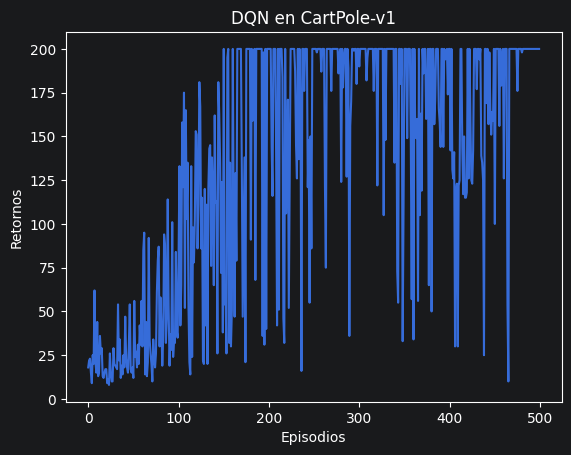

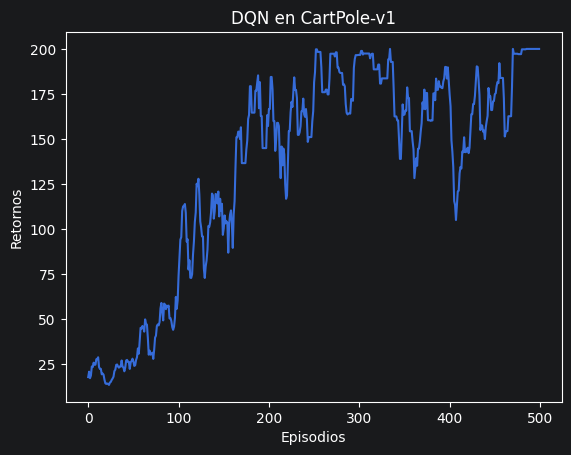

In [13]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DQN en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('DQN en {}'.format(env_name))
plt.show()

# Reto 5
Pruebe la red entenada en el sistema CartPole y vea lo resultados. Es bueno el modelo? Si? No? Por que?

In [16]:
#Obtener estado inicial
env = gym.make('CartPole-v1', render_mode = 'human')
for _ in range(10):
    state, _ = env.reset(seed=0)
    episode_return = 0
    for step in range(200):
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
        # Escoger la mejor acción de la q_net
        with torch.no_grad():  # No necesitamos calcular gradientes en evaluación
            action = agent.q_net(state_tensor).max(1)[1].item()  # [1] para obtener el índice de la mejor acción
        #Obtener s', r', donde e info
        state,reward,terminated,truncated,_ = env.step(action)
        done = terminated or truncated
        episode_return += reward
    
        if done:
            break
    print(f'Retorno obtenido {episode_return}')
# Cerrar el ambiente
env.close()

Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0
Retorno obtenido 200.0


In [17]:
torch.save(agent.q_net.state_dict(),"model_weights.pth")